# ML미니과제1 다이아몬드 가격 예측

[] 노트북 한개로 M1부터 M5까지 순서대로 진행 미션마다 마크다운 셸로 제목 달고 미션의 생각해본 질문 답을 같은 마크다운 셸에 적기       
[] 무작위가 들어가는 곳은 모두 random_start=42로 고정      
[] 각 미션 힌트는 막혔을때만. 확인용 기준값은 다 하고 펴기. 정답코드없음. 수업노트북 다시 찾아보는게 좋은 힌트. 

## M1 데이터 불러오기
> 목표: diamonds 데이터를 내려받아 크기, 자료형, 기초 통계를 확인한다 

[O] mini-diamond 프로젝트를 만들고 scikit-learn, pandas, numpy, matplotlib, seaborn, ipykernel을 설치     
[O] 노트북 첫 셀에 import와 한글 폰트 설정을 넣는다(1장 2강 Lab7 셸 재사용)     
[O] sns.load_dataset("diamonds")로 불러와 df에 담고, 크기와 앞 5행을 본다       
[O] 각 열의 자료형과 빈칸 개수를 확인한다        
[X] 숫자 열의 기초 통계를 보고 이상해 보이는 값을 두 가지 이상 찾아 적는다      

- 생각해볼 질문: price의 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 차이는 가격 분포에 대해 무엇을 말해 주나요? 
- 답: price는 평균이 더 큽니다. 중앙값보다 평균값이 더 높으니까 뭔가 튀는 값이 있는것같습니다. 
- 교안답: 평균(약 3,933)이 중앙값(2,401)보다 큽니다. 값이 큰 쪽의 소수(아주 비싼 다이아몬드)가 평균을 끌어올렸다는 뜻으로, 분포가 오른쪽으로 꼬리가 긴 모양입니다(M3 히스토그램에서 확인). '보통' 다이아몬드의 가겨은 평균보다 중앙값이 더 잘 나타냅니다

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import platform
import matplotlib.pyplot as plt

os_name = platform.system()
plt.rcParams["font.family"] = "Malgun Gothic"

# 1-1 데이터 내려받기 
# diamonds 데이터를 불러와 크기와 앞 5행을 봅니다 
df = sns.load_dataset("diamonds")
print(df.shape)
df.head()
# df.shape

# 1-2 자료형과 빈칸
# df.info()
# 1-3 기초 통계 
# 숫자 열의 기초 통계를 보고 이상한 값을 두 가지 이상 찾습니다
df.describe().round(2)
# print("평균:", round(df["price"].mean(), 2), "| 중앙값:", df["price"].median())
# mean_price = df["price"].mean()
# df['z'].value_counts
# print(df["z"].quantile([0.25, 0.5, 0.75]))
# df["z"].describe()[["25%", "50%", "75%"]]

# q1 = df["z"].quantile(0.25)
# q3 = df["z"].quantile(0.75)
# iqr = q3 - q1
# upper = q3 + 1.5*iqr
# print(f"Q1={q1:.2f}, Q3={q3:.2f} IQR={iqr:2f} UPPER={upper:.2f}")
# print("이상 보석갯수:", (df["y"] > upper).sum(), "개")
# print("남은 빈칸:", df["price"].isnull().sum())
# df.loc[empty_price, ["sex", "age", "class"]].head()

(53940, 10)


,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


## M2 이상치 정리
> 목표: 말이 안 되는 값을 찾아 근거와 함께 제거하고 정리된 표 clean을 만든다 

[O] x, y, z 각각 0인 값이 몇 개인지 센다          
[!O] 셋 중 하나라도 0인 행이 몇 개인지 세고, 그 행들을 직접 본다          
[!O] y나 z가 20mm를 넘는 행을 찾아 직접 본다 왜 이상한 값이라고 판단할 수 있는지 적는다       
[!O] 두 종류의 이상한 행을 모두 뺀 clean 표를 만들고 제거 전후 행 수를 출력한다       

- 생각해 볼 질문: 어떤 행을 왜 지웠나요? 비싼 다이아몬드는 왜 지우면 안 되나요? 
- 답: X
- 교안 답: <br>
지운 행: <br>
1) x, y, z중 0이 있는 20행(측정, 입력 누락, 크기가 0mm인 다이아몬드는 없음)<br>
2) y나 z가 20mm를 넘는 3행(carat은 정상인데 한 번만 30-59mm->소수점 입력 실수로 추정)<br>
3) 비싼 다이아몬드를 지우면 안 되는 이유: 큰 carat, 좋은 등급의 다이아몬드는 틀린값이 아니라 진짜 값. 가격이 크다는 이유만으로 지우면 비싼 쪽을 예측하지 못하는 모델이 됨. 

In [ ]:
zero = (df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)
print("0이 있는 행:", zero.sum())
df[zero].head()

df[(df["y"] > 20) | (df["z"] > 20)]

bad = zero | (df["y"] > 20) | (df["z"] > 20)
clean = df[~bad].copy()
print(len(df), "->", len(clean) ,"(제거", bad.sum(), "행")


53940 -> 53917 (제거 23 행


## M3 그래프와 상관계수
> 목표: 가격의 분포와 무게-가격 관계를 그리고, 가격을 예측할 특성 하나를 고른다 

[!O] price의 히스토그램을 그리고 평균, 중앙값을 세로선으로 표시한다          
[!O] carat과 price의 산점도를 그린다(점이 많으면 3,000개만 무작위로 뽑아 그린다)           
[!O] 숫자 열끼리 상관계수를 구해 price와 상관이 큰 순서로 정렬한다        
[!O] 가격 예측에 쓸 특성 하나를 고르고 이유를 적는다        

- 생각해 볼 질문: 왜 carat을 (또는 다른 열을) 골랐나요? 산점도에서 직선 하나로 맞추기 어려워 보이는 부분은 어디인가요? 
- 답: X
- 교안 답: <br>
carat을 고른 이유: price와의 상관이 0.922로 가장 크고 무게라는 의미도 가장 이해하기 쉽습니다. (x,y,z는 모두 '크기'라 같은 이야기를 합니다)  <br>
직선으로 맞추기 어려운 곳: <br>
- 점들이 직선이 아니라 살짝 위로 휘는 모양 <br>
- carat이 큰 구간에서 같은 무게인데도 가격이 위아래로 넓게 퍼지는 부분 

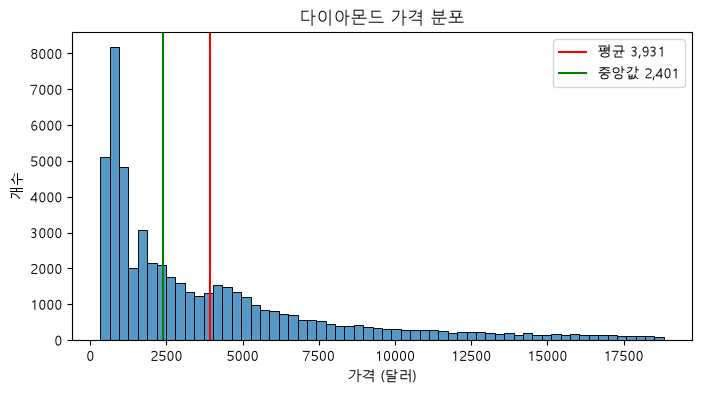

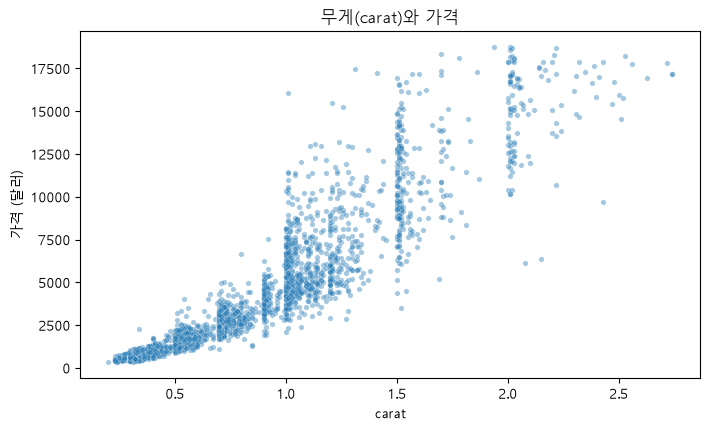

price    1.000
carat    0.922
y        0.889
x        0.887
z        0.882
table    0.127
depth   -0.011
Name: price, dtype: float64

In [12]:
# 그림(fig)과 그래프를 그릴 칸(ax) 만들기 
fig, ax = plt.subplots(figsize=(8, 4))
# 히스토그램: 값이 어느 구간에 많이 몰려 있는지
sns.histplot(clean["price"], bins=60, ax=ax)
ax.axvline(clean["price"].mean(), color="red", label=f'평균 {clean["price"].mean():,.0f}')
ax.axvline(clean["price"].median(), color="green", label=f'중앙값 {clean["price"].median():,.0f}')
ax.set(title="다이아몬드 가격 분포", xlabel="가격 (달러)", ylabel="개수")
ax.legend()
# plt.show

# 무작위로 일부 행만 뽑기(random_state로 매번 같게) 
sample = clean.sample(3000, random_state=42)
# 그림(fig)과 그래프를 그릴 값(ax) 만들기
fig, ax = plt.subplots(figsize=(8, 4.5))
# 산점도 : 두 값의 관계를 점으로 
sns.scatterplot(data=sample, x="carat", y="price", alpha=0.4, s=15, ax=ax)
ax.set(title="무게(carat)와 가격", xlabel="carat", ylabel="가격 (달러)")
plt.show()

clean.select_dtypes("number").corr()["price"].sort_values(ascending=False).round(3)

## M4 무게로 가격 예측
> 목표: carat 하나로 선형 회귀를 학습해 w.b의 뜻을 설명하고, 새 다이아몬드의 가격을 예측하고, 직선을 그림으로 확인한다

[!O] X_train의 carat 열 하나로 LinearRegression을 학습하고 w(기울기), b(절편)를 출력한다     
[!O] w의 뜻을 한 문장으로 적는다("뭭가 1캐럿 늘면 가격이 약 7,756달러 오릅니다")          
[!O] 0.25, 0.5, 1.0, 2.0 캐럿 다이아몬드의 가격을 예측한다. 이상한 결과가 있나?         
[!O] 학습 데이터 3,000개의 산점도에 찾은 직선(빨강)과 학습 데이터의 평균 가격(회색 가로선)을 겹쳐 그린다      

- 생각해볼 질문: 0.25 캐럿 다이아몬드의 예상가가 음수인 이유는 무엇일까요? 직선이 실제 점들보다 아래 위로 지나가는 구간은 각각 어디인가요? 평균 가격 가로선과 비교하면 직선은 무엇이 나아졌나요? 
- 답: X
- 교안답: <br>
음수인 이유: 절편b가 -2, 256으로 음수라서 직선이 약 0.29캐럿보다 작은 구간에서 0아래로 내려갑니다 실제 가격은 위로 휘는 곡선이라 작은 돌에서 직선과 어긋납니다 <br>
아래로 지나가는 구간: 작은 돌 (약 0.4캐럿 미만) <br>
위로 지나가는 구간: 0.5~1캐럿 근처<br>
평균선과 비교: 평균선은 무게와 상관없이 같은 값을 답해 작은 돌은 비싸게 큰 돌은 싸게 틀립니다 직선은 무게가 늘수록 함께 올라가서 점들을 훨씬 잘 따라갑니다  

w = 7,755.9 b = -2,255.9
가격 = 7,756 x carat + (-2,256)


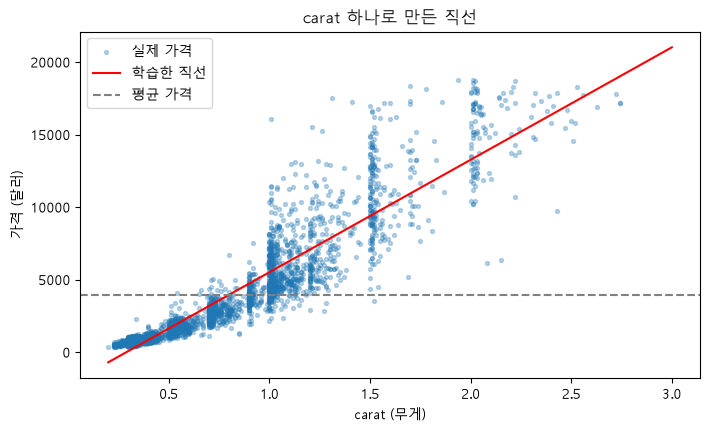

In [17]:
from sklearn.linear_model import LinearRegression

# 선형 회귀 모델 만들기 (아직 학습 전)
model = LinearRegression()
# 학습: 입력 X(carat 한 열, 대괄호 두 겹)와 정답 y(price)로 직선의 w, b를 찾는다
model.fit(clean[["carat"]], clean["price"])
# coef_ = 학습된 기울기(w), intercept_ = 절편(b)
w, b = model.coef_[0], model.intercept_
print(f"w = {w:,.1f} b = {b:,.1f}")
print(f"가격 = {w:,.0f} x carat + ({b:,.0f})")

new = pd.DataFrame({"carat": [0.25, 0.5, 1.0, 2.0]})
# 학습한 모델로 예측하기 
new["예상가(달러)"] = model.predict(new).round()
# new

# 데이터에서 무작위로 3,000개만 뽑기 (random_state로 매번 같게) 
vs = clean.sample(3000, random_state=42)

# 그림(fig)과 그래프를 그릴 칸(ax) 만들기 
fig, ax = plt.subplots(figsize=(8, 4.5))
# 산점도: 실제 가격
ax.scatter(vs["carat"], vs["price"], s=8, alpha=0.3, label="실제 가격")
# 직선은 양 끝 두 점의 예측값을 이으면 된다 
line_x = pd.DataFrame({"carat": [0.2, 3.0]})
ax.plot(line_x["carat"], model.predict(line_x), color="red", label="학습한 직선")
# 가로선: 아무것도 배우지 않은 모델(평균 가격) 
ax.axhline(clean["price"].mean(), color="gray", linestyle="--", label="평균 가격")
ax.set(xlabel="carat (무게)", ylabel="가격 (달러)", title="carat 하나로 만든 직선")
ax.legend()
plt.show()



## M5 특성 하나씩 직선 만들기
> 목표: 숫자 6개 열 각각 하나로 직선을 만들어 그림으로 비교하고 가격을 예측할 열을 고른 이유를 설명한다 

[!O] 숫자 6개 열 각각 하나로 LinearRegression을 학습한다         
[!O] 학습 데이터 3,000개의 산점도와 각 열의 직선을 2행 3열 그림 한 장에 그린다        
[!O] 직선이 점들을 잘 따라가는 열과 못 따라가는 열을 적는다<br>
: 잘따라감: carat, x, y, z, 못따라감: depth, table          
[!O] 열마다 w(기울기)와 열의 범위(가장 작은 값~가장 큰 값)를 표 하나로 정리하고 w가 크면 더 좋은 열인지 생각해 적는다<br>
: [교안의 답] 아닙니다. w는 '그 열이 1 늘 때 가격이 얼마나 변하나' 이므로 열의 단위와 범위에 따라 크기가 달라집니다. z는 1.1~7.0mm안에서 table은 43~95안에서 움직이므로 w숫자끼리 크기를 비교할 수 없습니다 열을 비교할때는 1) 5-1처럼 그림으로 직선이 점들을 얼마나 따라가는지 보거나 2) M3의 상관계수(-1~1, 단위와 무관)를 씁니다           
[!O] M3의 상관계수 순서와 그림이 같은 이야기를 하는지 확인한다         

- 답: <br>
carat의 근거: 그림에서 점들이 직선 둘레에 가장 좁게 모여 있고 상관계수는 0.922로 가장 큽니다<br>
22배 좋은 열이 아닙니다: w는 열의 단위와 범위에 따라 달라지는 값입니다(z는 몇 mm안에서 table은 수십% 범위에서 움직임)<br>
대신 볼것: 직선이 점들을 얼마나 따라가는지(그림) 그리고 단위와 무관한 상관계수 

C:\Users\USER\AppData\Local\Temp\ipykernel_9660\4026240800.py:18: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
c:\Users\USER\kant_study\assignment\ML\mini01\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


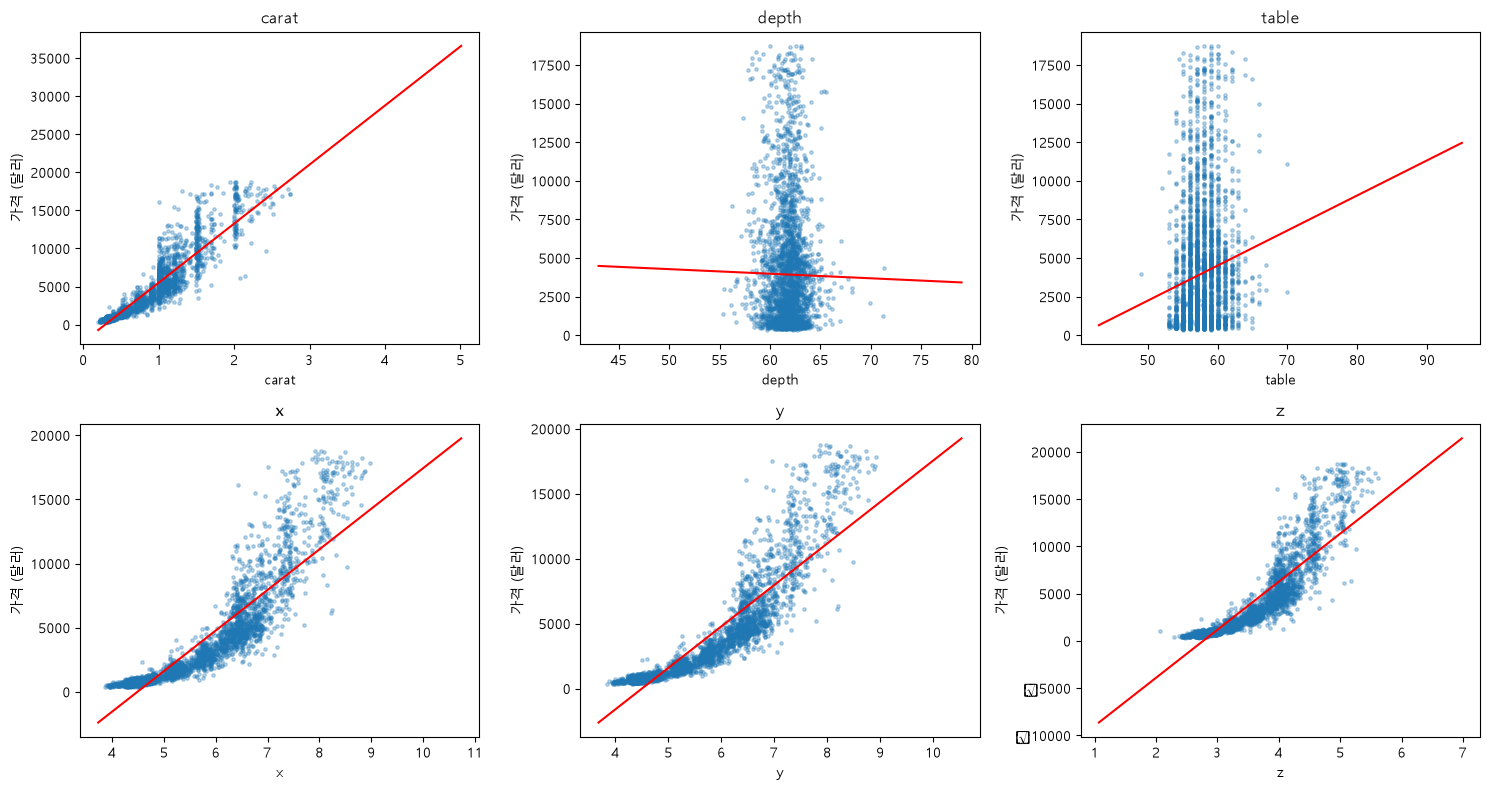

,열,w (기울기),열의 범위
0,carat,7755.9,0.2 ~ 5.0
1,depth,-29.7,43.0 ~ 79.0
2,table,227.1,43.0 ~ 95.0
3,x,3160.2,3.7 ~ 10.7
4,y,3189.1,3.7 ~ 10.5
5,z,5085.4,1.1 ~ 7.0


In [19]:
# 숫자 6개 열 이름
num_cols = ["carat", "depth", "table", "x", "y", "z"]
vs = clean.sample(3000, random_state=42)

# 2행 3열 = 칸 6개짜리 도화지 
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
# 칸 6개와 열 이름 6개를 하나씩 짝지어 반복 
for ax, col in zip(axes.ravel(), num_cols):
    # 이 열 하나로 직선 학습
    m = LinearRegression().fit(clean[[col]], clean["price"])
    # 점: 실제 가격
    ax.scatter(vs[col], vs["price"], s=6, alpha=0.3)
    # 직선: 열의 가장 작은 값과 가장 큰 값에서의 예측을 이음
    ends = pd.DataFrame({col: [clean[col].min(), clean[col].max()]})
    ax.plot(ends[col], m.predict(ends), color="red")
    ax.set(title=col, xlabel=col, ylabel="가격 (달러)")

fig.tight_layout()
plt.show()

rows = []
for col in num_cols:
    m = LinearRegression().fit(clean[[col]], clean["price"])
    value_range = f"{clean[col].min():.1f} ~ {clean[col].max():.1f}" #이 열의 가장 작은 값 ~ 가장 큰 값
    rows.append({"열": col, "w (기울기)": round(m.coef_[0], 1), "열의 범위": value_range})
pd.DataFrame(rows)

# 마무리/이 과제에서 기억할 것 

1. 데이터는 모델 전에 먼저 점검합니다. shape, info, describe로 빈칸과 이상한 값을 찾습니다 
2. 이상치는 근거와 함께 지웁니다. 틀린 값(크기0, 소수점 실수)은 지우고, 비싼 값 같은 진짜 값은 지우지 않습니다. 
3. 그래프와 상관계수로 예측에 쓸 열을 고릅니다. 상관계수가 클수록 직선이 점들을 잘 따라갑니다 
4. 선형 회귀의 w는 '1늘 때 변하는 양', b는 직선의 위치값입니다 직선은 일부 구간(작은 돌, 큰 돌)에서 틀리고 음수 가격도 낼 수 있습니다
5. w끼리 크기를 비교하지 않습니다. 열을 비교할 때는 그림이나 단위와 무관한 상관계수를 씁니다 